# Pepper Berry Detection — YOLOv8s



# Pepper Care ML — YOLOv8 Training

## 1. Environment & GPU check

In [1]:
!nvidia-smi

Mon Jul 27 01:48:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Mount Google Drive

In [ ]:
from google.colab import drive  #connect the google drive//
drive.mount('/content/drive')

## 3. One-time dataset setup (already executed)

Located `PEPPER_BERRY`, created `NEW_DATASET`, extracted the OneDrive zips and the three Roboflow YOLOv8 dataset zips (`pest_detection`, `pepper_berry_detection`, `leaf_diseases`), deleting each zip after extraction. **These cells don't need to be run again.**

// These cells locate the dataset, create folders, and extract ZIP files.

In [ ]:
import os      # Find the dataset folder  (Dataset setup) //

# Locate PEPPER_BERRY (checks MyDrive top level first, then one level deep)
base = '/content/drive/MyDrive'
candidates = [os.path.join(base, 'PEPPER_BERRY')]
candidates += [os.path.join(base, d, 'PEPPER_BERRY') for d in os.listdir(base)
               if os.path.isdir(os.path.join(base, d))]

folder = next((p for p in candidates if os.path.isdir(p)), None)
print('Found at:', folder)

if folder:
    for root, dirs, files in os.walk(folder):
        depth = root[len(folder):].count(os.sep)
        indent = '    ' * depth
        print(f'{indent}{os.path.basename(root)}/  ({len(files)} files)')
        if depth >= 2:          # don't descend deeper than 2 levels
            dirs.clear()
        for f in files[:5]:     # show first 5 files per folder
            print(f'{indent}    {f}')
        if len(files) > 5:
            print(f'{indent}    ... and {len(files) - 5} more')
else:
    print('PEPPER_BERRY not found — top level of MyDrive is:')
    print(os.listdir(base))

In [12]:
import os, zipfile, glob   #Create a dataset folder And extract ZIP files (Dataset setup)  //

pepper = '/content/drive/MyDrive/PEPPER_BERRY'   # adjust if your path differs
new_dataset = os.path.join(pepper, 'NEW_DATASET')
os.makedirs(new_dataset, exist_ok=True)
print('Created:', new_dataset)

# Find zip files inside PEPPER_BERRY
zips = glob.glob(os.path.join(pepper, '*.zip'))
print('Zip files found:', zips)

for z in zips:
    print(f'\nExtracting {os.path.basename(z)} ...')
    with zipfile.ZipFile(z) as zf:
        zf.extractall(new_dataset)
    print('Done.')

print('\nContents of NEW_DATASET:')
print(os.listdir(new_dataset))

Created: /content/drive/MyDrive/PEPPER_BERRY/NEW_DATASET
Zip files found: []

Contents of NEW_DATASET:
['pest_detection']


In [14]:
import os, zipfile, glob  #extracted the downloaded dataset And organized their contents into separate folders. This made the datasets accessible For  model training. (Dataset setup) //

new_dataset = '/content/drive/MyDrive/PEPPER_BERRY/NEW_DATASET'

for zip_path in glob.glob(os.path.join(new_dataset, '*.zip')):
    name = os.path.basename(zip_path)
    # folder name: strip .zip / .yolov8, e.g. "Pepper Berry Detection.yolov8" -> "pepper_berry_detection"
    folder = name.replace('.zip', '').replace('.yolov8', '').strip().lower().replace(' ', '_')
    out_dir = os.path.join(new_dataset, folder)

    os.makedirs(out_dir, exist_ok=True)
    print(f'Extracting {name} -> {out_dir} ...')
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(out_dir)
    print('  done, deleting zip')
    os.remove(zip_path)

print('\nContents of NEW_DATASET:')
print(os.listdir(new_dataset))


Contents of NEW_DATASET:
['pest_detection']


# 4. Pepper Berry Detection — YOLOv8

Object detection model for pepper berries using the Roboflow-exported dataset at
`NEW_DATASET/pepper_berry_detection`.

## 4.1 Create training workspace

#defined separate paths For the dataset And training workspace //

In [15]:
import os #defined separate paths For the dataset And training workspace //

PEPPER = '/content/drive/MyDrive/PEPPER_BERRY'
DATASET_DIR = os.path.join(PEPPER, 'NEW_DATASET', 'pepper_berry_detection') #points to the pepper berry detection dataset.
TRAIN_DIR = os.path.join(PEPPER, 'pepper_berry_train')   # workspace where training runs and their outputs will be saved.

os.makedirs(TRAIN_DIR, exist_ok=True)
print('Dataset dir :', DATASET_DIR, '| exists:', os.path.isdir(DATASET_DIR))
print('Train dir   :', TRAIN_DIR, '| exists:', os.path.isdir(TRAIN_DIR))

Dataset dir : /content/drive/MyDrive/PEPPER_BERRY/NEW_DATASET/pepper_berry_detection | exists: False
Train dir   : /content/drive/MyDrive/PEPPER_BERRY/pepper_berry_train | exists: True


## 4.2 Dataset organization

Inspect the folder structure, read `data.yaml` (classes), and count images/labels per split. Also parse every label file to get the class-instance distribution and flag images that have no annotations.

//Ensure the data set and labels arranged properly before training

In [16]:
import os, glob, yaml
from collections import Counter

# --- Folder structure ---
print('=== Folder structure ===')
for root, dirs, files in os.walk(DATASET_DIR):
    depth = root[len(DATASET_DIR):].count(os.sep)
    print(f"{'    ' * depth}{os.path.basename(root) or 'pepper_berry_detection'}/  ({len(files)} files)")
    dirs.sort() #check whether the expected image and label folders were present)

# --- data.yaml ---
yaml_path = os.path.join(DATASET_DIR, 'data.yaml')
with open(yaml_path) as f:
    data_cfg = yaml.safe_load(f)
print('\n=== data.yaml ===')
for k, v in data_cfg.items():
    print(f'{k}: {v}')
class_names = data_cfg['names'] #The data.yaml allows the training process to locate the images and their annotations correctly


# Count images and label files
print('\n=== Split summary ===')
for split in ['train', 'valid', 'test']:
    img_dir = os.path.join(DATASET_DIR, split, 'images')
    lbl_dir = os.path.join(DATASET_DIR, split, 'labels')
    if not os.path.isdir(img_dir):
        print(f'{split}: (missing)')
        continue

    images = glob.glob(os.path.join(img_dir, '*'))
    labels = glob.glob(os.path.join(lbl_dir, '*.txt'))

    class_counts = Counter() #Read the label files and count classes
    empty_labels = 0
    for lf in labels:
        with open(lf) as f:
            lines = [l for l in f.read().splitlines() if l.strip()]
        if not lines:
            empty_labels += 1
        for line in lines:
            class_counts[int(line.split()[0])] += 1

    print(f'\n{split}: {len(images)} images, {len(labels)} label files, ' # // Print the split summary and class distribution //
          f'{empty_labels} empty (background) labels')
    total = sum(class_counts.values())
    for cls_id, cnt in sorted(class_counts.items()):
        name = class_names[cls_id] if cls_id < len(class_names) else f'?{cls_id}'
        print(f'   {name:<30} {cnt:>6} boxes ({cnt/total:.1%})')

=== Folder structure ===


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/PEPPER_BERRY/NEW_DATASET/pepper_berry_detection/data.yaml'

## 4.3 Image characteristics

Check image dimensions, file sizes and brightness across the train split, then visualize a few sample images with their ground-truth bounding boxes drawn.

Task 1 — Analyze image characteristics: Inspect image dimensions, file sizes and brightness for a sample of the training images.

Task 2 — Visualize ground-truth bounding boxes

The first task helps to understand the data's characteristics. The second helps to visually check whether the annotations align with the objects.

Sampled 200 of 298 train images

Image dimensions (W x H):
   3072 x 4096: 19 images
   1792 x 2390: 17 images
   4080 x 3060: 5 images
   720 x 538: 5 images
   718 x 536: 4 images
   718 x 538: 4 images
   700 x 560: 3 images
   2390 x 1792: 3 images
   721 x 538: 3 images
   714 x 536: 3 images
   721 x 539: 3 images
   717 x 541: 3 images
   719 x 538: 2 images
   717 x 536: 2 images
   727 x 540: 2 images
   720 x 541: 2 images
   721 x 533: 2 images
   697 x 556: 2 images
   718 x 539: 2 images
   723 x 538: 2 images
   717 x 534: 2 images
   721 x 540: 2 images
   718 x 544: 2 images
   717 x 538: 2 images
   710 x 542: 1 images
   540 x 720: 1 images
   720 x 1280: 1 images
   2098 x 3234: 1 images
   771 x 1868: 1 images
   1801 x 2618: 1 images
   724 x 535: 1 images
   696 x 577: 1 images
   715 x 534: 1 images
   701 x 557: 1 images
   2388 x 4025: 1 images
   693 x 551: 1 images
   698 x 557: 1 images
   697 x 555: 1 images
   690 x 555: 1 images
   1836 x 4080: 1 images
 

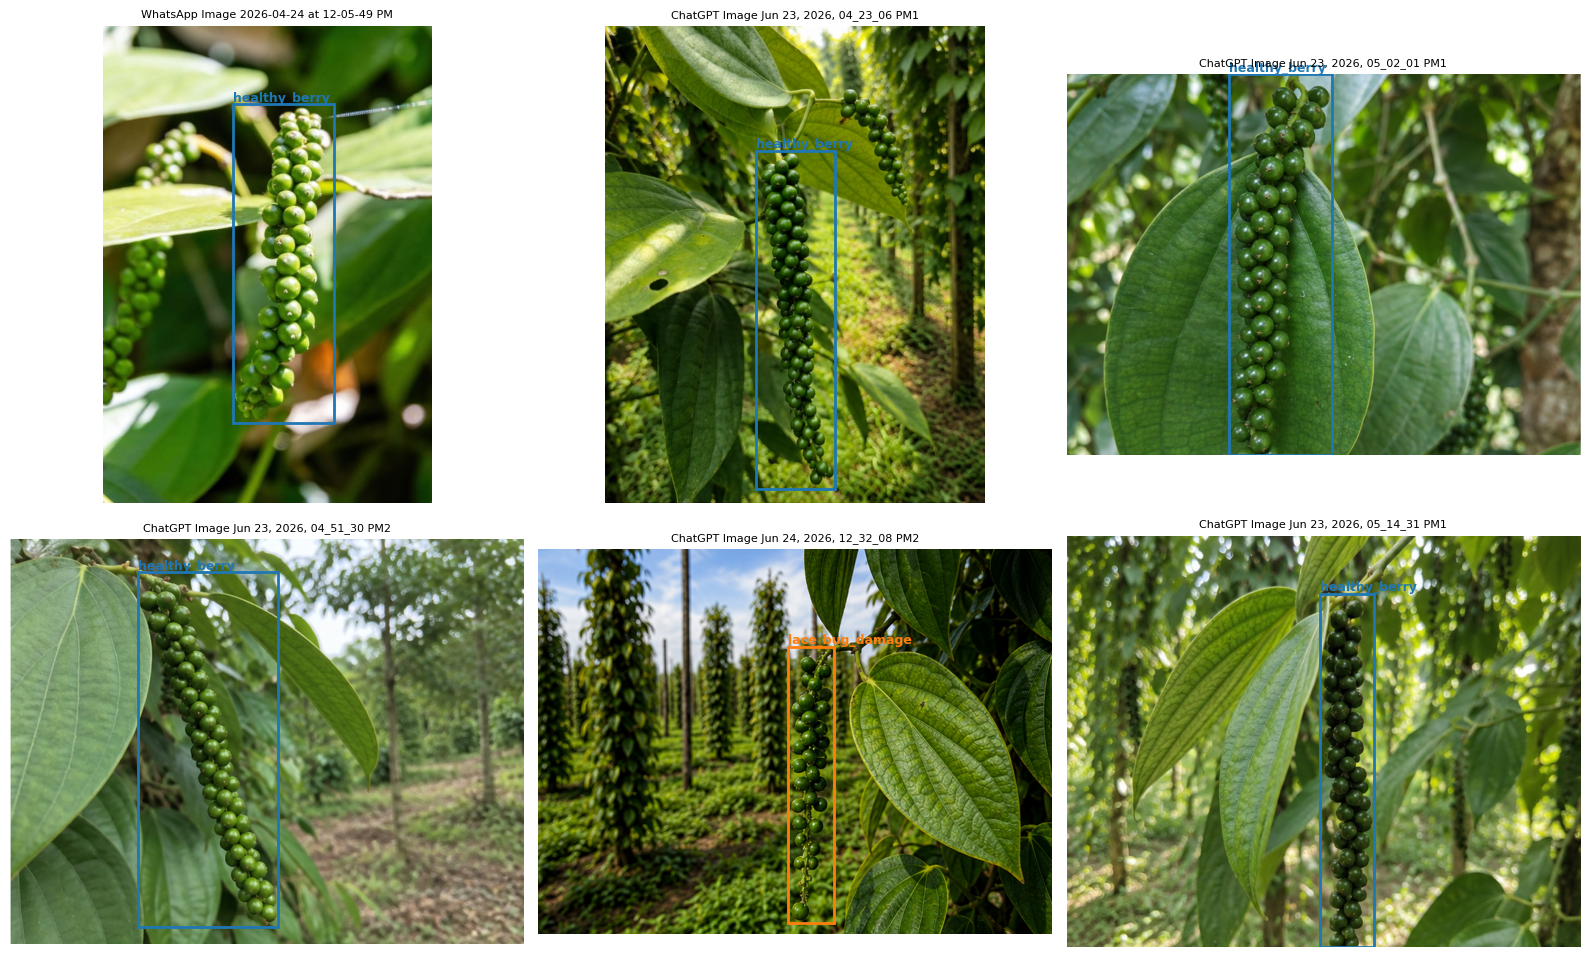

In [9]:
import os, glob, random
from collections import Counter
import numpy as np #use NumPy to convert grayscale image pixels  and calculate the average brightness
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches


#Task 1: Analyze image characteristics
# //Select the training images
train_imgs = sorted(glob.glob(os.path.join(DATASET_DIR, 'train', 'images', '*')))
sample = random.sample(train_imgs, min(200, len(train_imgs))) #ensures that the code selects no more than 200 images and never requests more images than are available. 
#Why not inspect every image: Google Drive file I/O can be slow

# Analyze image dimensions / size / brightness 
    # To understand the resolutions present in the dataset
    #To identify variation in image sizes
    #To understand the preprocessing and resizing that may be needed during model training

dims, file_kb, brightness = Counter(), [], []
for p in sample:
    with Image.open(p) as im:
        dims[im.size] += 1
        arr = np.asarray(im.convert('L'), dtype=np.float32)
    brightness.append(arr.mean())
    file_kb.append(os.path.getsize(p) / 1024)

print(f'Sampled {len(sample)} of {len(train_imgs)} train images\n')
print('Image dimensions (W x H):')
for size, cnt in dims.most_common():
    print(f'   {size[0]} x {size[1]}: {cnt} images')
print(f'\nFile size : min {min(file_kb):.0f} KB | mean {np.mean(file_kb):.0f} KB | max {max(file_kb):.0f} KB')
print(f'Brightness: min {min(brightness):.0f} | mean {np.mean(brightness):.0f} | max {max(brightness):.0f}  (0=black, 255=white)')



#Task 2 : Visualize ground-truth bounding boxes
#check whether the annotations align with the objects
def yolo_to_xyxy(line, w, h):
    cls, xc, yc, bw, bh = line.split()[:5]
    xc, yc, bw, bh = float(xc) * w, float(yc) * h, float(bw) * w, float(bh) * h
    return int(cls), xc - bw / 2, yc - bh / 2, bw, bh

show = random.sample(train_imgs, min(6, len(train_imgs)))
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
colors = plt.cm.tab10.colors
for ax, img_path in zip(axes.flat, show): # //Draw the ground-truth bounding boxes
    im = Image.open(img_path)
    ax.imshow(im)
    lbl_path = img_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt' # //
    if os.path.exists(lbl_path):
        with open(lbl_path) as f:
            for line in f.read().splitlines():
                if not line.strip():
                    continue
                cls, x, y, bw, bh = yolo_to_xyxy(line, *im.size)
                ax.add_patch(patches.Rectangle((x, y), bw, bh, linewidth=2,
                             edgecolor=colors[cls % 10], facecolor='none'))
                ax.text(x, y - 4, class_names[cls], color=colors[cls % 10],
                        fontsize=9, weight='bold')
    ax.set_title(os.path.basename(img_path)[:40], fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.4 Install Ultralytics (YOLOv8)

Import the library & check if its imporeted properly

In [3]:
%pip install -q ultralytics

import ultralytics   #import the library
ultralytics.checks() #check the imported library avauilability

Ultralytics 8.4.101 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 46.7/112.6 GB disk)


## 4.5 Prepare dataset for training

Two steps:
1. **Copy the dataset from Drive to Colab local disk** (`/content/`) — training reads every image every epoch, and Drive I/O is ~10× slower than local disk. The dataset is small (~430 images) so the copy takes seconds.
2. **Rewrite `data.yaml` with absolute paths** — the Roboflow export uses relative paths (`../train/images`) that resolve incorrectly; absolute paths remove any ambiguity.

Copy the dataset from Google Drive to Colab's local disk and update data.yaml so YOLO can locate the images

why?
 Reading them from local disk can be faster than repeatedly accessing files through Google Drive.

In [7]:
import os, shutil, yaml

LOCAL_DATASET = '/content/pepper_berry_detection'

# 1. Copy dataset from Drive to local disk (skip if already copied this session)
if not os.path.isdir(LOCAL_DATASET):
    print('Copying dataset from Drive to local disk ...')
    shutil.copytree(DATASET_DIR, LOCAL_DATASET)
    print('Copy done.')
else:
    print('Local copy already exists, skipping.')

# 2. Rewrite data.yaml with absolute paths(local path)
local_yaml = os.path.join(LOCAL_DATASET, 'data.yaml')
with open(local_yaml) as f:
    cfg = yaml.safe_load(f)

cfg['train'] = os.path.join(LOCAL_DATASET, 'train', 'images')
cfg['val']   = os.path.join(LOCAL_DATASET, 'valid', 'images')
cfg['test']  = os.path.join(LOCAL_DATASET, 'test', 'images')

with open(local_yaml, 'w') as f:
    yaml.dump(cfg, f, sort_keys=False)

print('\ndata.yaml now points to:')
for k in ['train', 'val', 'test']:
    print(f"  {k}: {cfg[k]}  | exists: {os.path.isdir(cfg[k])}")
print('classes:', cfg['names'])

Copying dataset from Drive to local disk ...


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/PEPPER_BERRY/NEW_DATASET/pepper_berry_detection'

## 4.6 Train YOLOv8

Baseline run: **yolov8s** pretrained on COCO, fine-tuned at `imgsz=640` for up to 100 epochs with early stopping (`patience=20`).

Results (weights, curves, confusion matrix) are written to **`pepper_berry_train/` in Drive** via `project=TRAIN_DIR`, so nothing is lost if Colab disconnects. Best weights end up at:
`pepper_berry_train/baseline_v8s/weights/best.pt`

Expect roughly 15–25 min on the T4.

In [12]:
from ultralytics import YOLO

model = YOLO('yolov8s.pt')   # small model — right size for ~300 train images

results = model.train(
    data=local_yaml,          # local dataset (fast I/O)
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,              # stop early if no val improvement for 20 epochs
    project=TRAIN_DIR,        # save runs to Drive — survives disconnects
    name='baseline_v8s',
    exist_ok=True,
    seed=42,                    #improve reproducibility, It helps us compare training runs more fairly
    plots=True,
)

Ultralytics 8.4.101 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pepper_berry_detection/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_v8s, nbs=64, nms=False, opset=None, optimize=False, optimizer=a

## 4.7 Evaluate on the test split

Load the best checkpoint and measure performance on the held-out test set (43 images the model never saw during training or early stopping).


//Evaluate how well the trained model performs on unseen images


In [13]:
import os
from ultralytics import YOLO

best_weights = os.path.join(TRAIN_DIR, 'baseline_v8s', 'weights', 'best.pt') #Builds the path to the saved best.pt model.
best = YOLO(best_weights)

metrics = best.val(data=local_yaml, split='test',
                   project=TRAIN_DIR, name='baseline_v8s_test', exist_ok=True)

print(f'\nmAP50      : {metrics.box.map50:.3f}')
print(f'mAP50-95   : {metrics.box.map:.3f}')
for i, name in enumerate(metrics.names.values()):
    print(f'{name:<20} P {metrics.box.p[i]:.3f} | R {metrics.box.r[i]:.3f} | mAP50 {metrics.box.ap50[i]:.3f}')

Ultralytics 8.4.101 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 188.9±100.3 MB/s, size: 1121.3 KB)
val: Scanning /content/pepper_berry_detection/test/labels... 43 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 43/43 36.5it/s 1.2s0.0s
val: /content/pepper_berry_detection/test/images/IMG_20260420_155228_jpg.rf.SGTRDTz92swFIsOBQ3Bm.jpg: corrupt JPEG restored and saved
val: /content/pepper_berry_detection/test/images/IMG_20260421_131137_jpg.rf.mWdxPKGpXcJcxc3ByyzP.jpg: corrupt JPEG restored and saved
val: /content/pepper_berry_detection/test/images/IMG_20260421_131320_jpg.rf.zfRMxkJkrLSEEYJ3FVwt.jpg: corrupt JPEG restored and saved
val: New cache created: /content/pepper_berry_detection/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.7s/it 5.0s2.8s
    

## 4.8 Predictions vs ground truth

Run the trained model on random test images and compare side by side:

- **Left panel = actual** (ground-truth: The correct object labels and bounding boxes provided in the dataset.)
- **Right panel = predicted** (The bounding boxes and classes predicted by your trained YOLOv8 model)

why? : To visually inspect whether the model detects the correct classes and locates objects in approximately the correct positions

Below the images, a summary table lists actual vs predicted class per image with a ✓/✗ verdict.

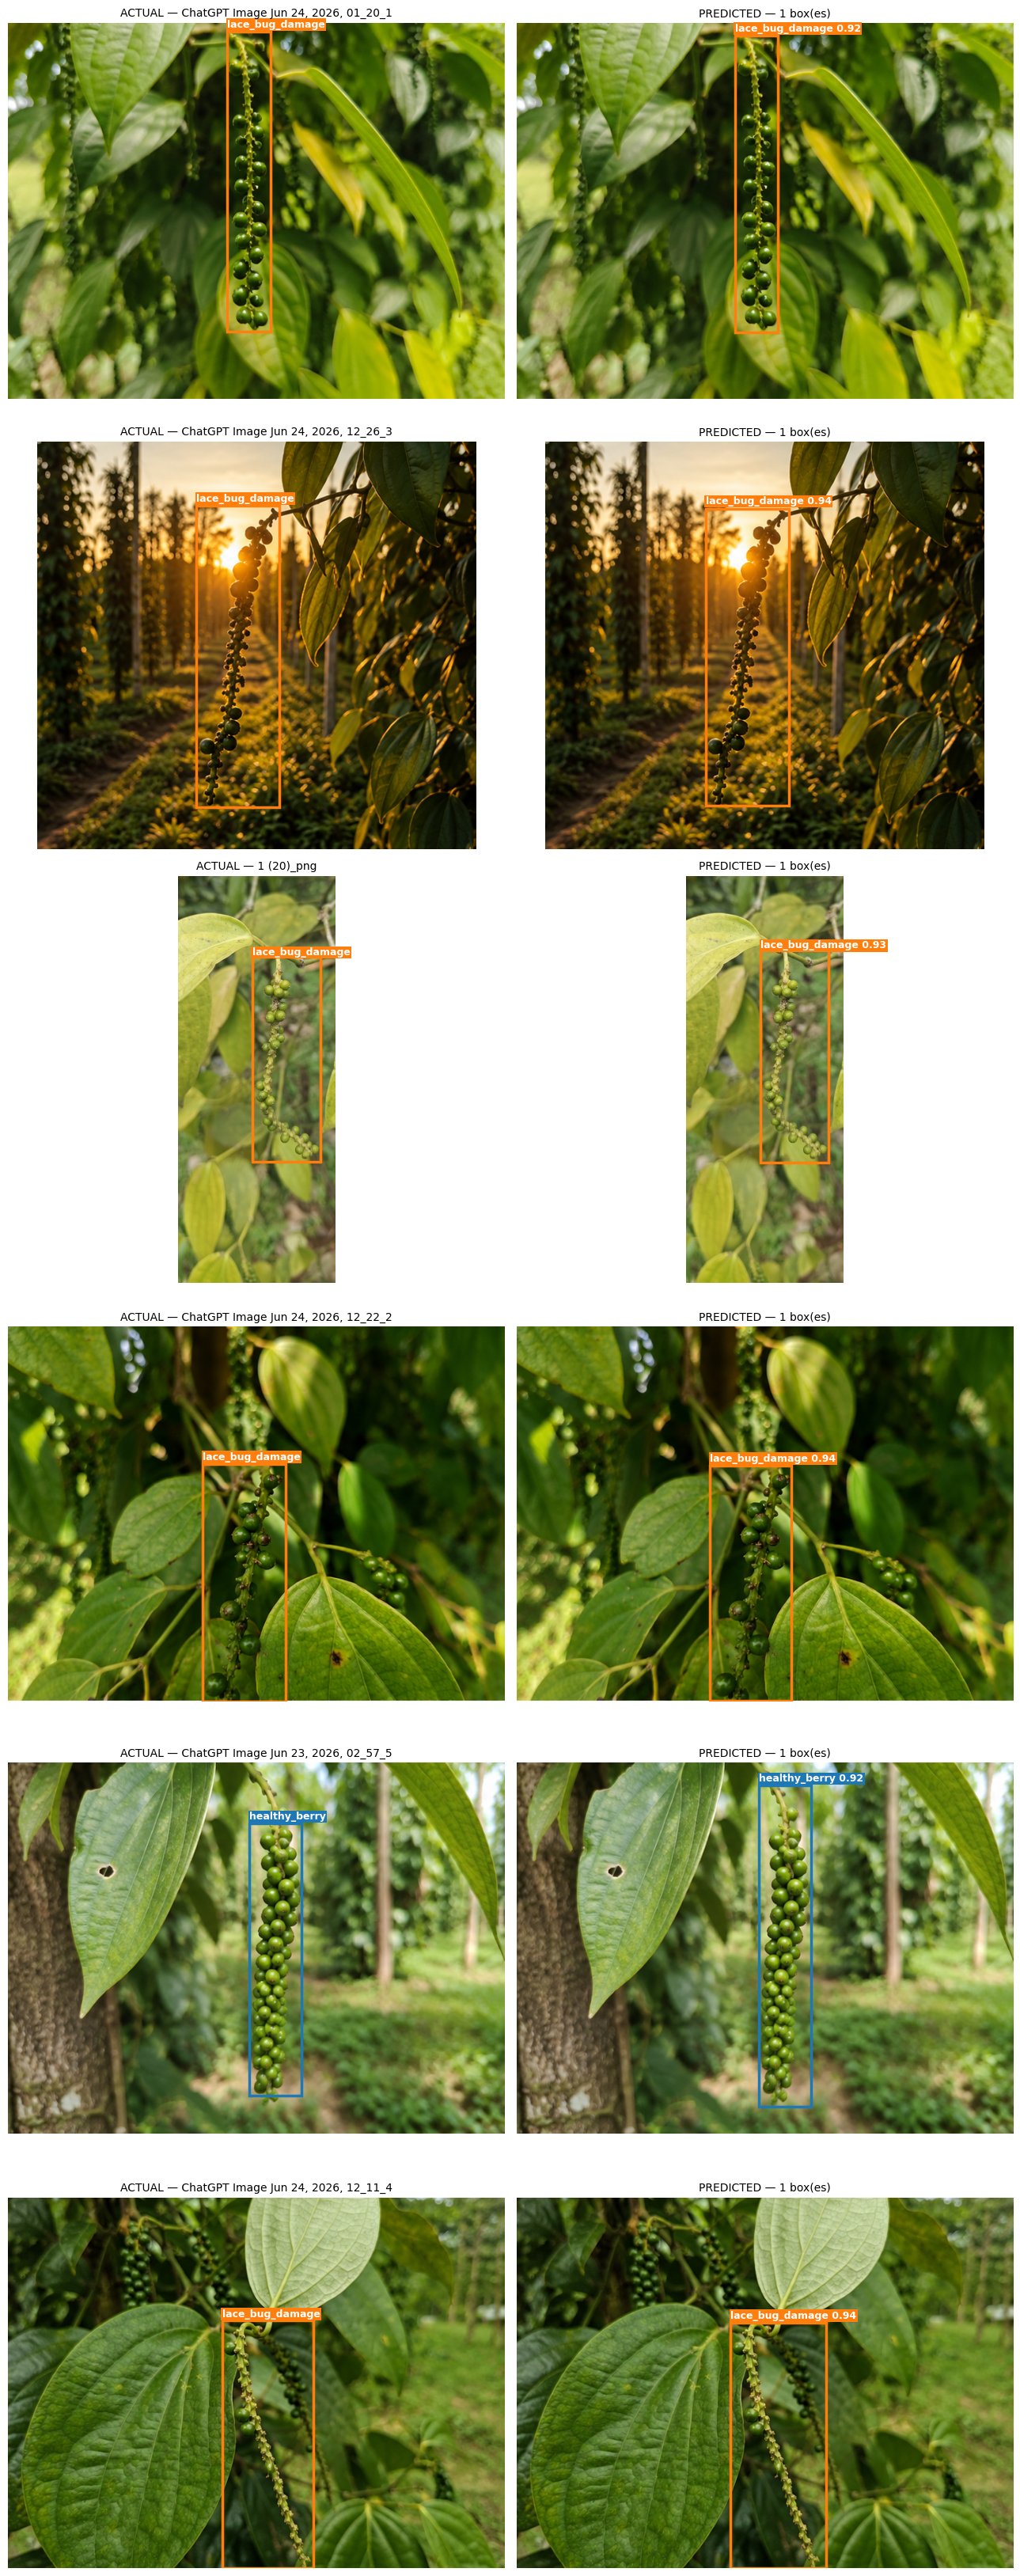


Image                                 Actual             Predicted (conf)                              OK
---------------------------------------------------------------------------------------------------------
ChatGPT Image Jun 24, 2026, 01_20_1   lace_bug_damage    lace_bug_damage (0.92)                        ✓
ChatGPT Image Jun 24, 2026, 12_26_3   lace_bug_damage    lace_bug_damage (0.94)                        ✓
1 (20)_png                            lace_bug_damage    lace_bug_damage (0.93)                        ✓
ChatGPT Image Jun 24, 2026, 12_22_2   lace_bug_damage    lace_bug_damage (0.94)                        ✓
ChatGPT Image Jun 23, 2026, 02_57_5   healthy_berry      healthy_berry (0.92)                          ✓
ChatGPT Image Jun 24, 2026, 12_11_4   lace_bug_damage    lace_bug_damage (0.94)                        ✓

6/6 correct


In [14]:
import os, glob, random
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from ultralytics import YOLO

N_SAMPLES = 6
CONF = 0.25

best = YOLO(os.path.join(TRAIN_DIR, 'baseline_v8s', 'weights', 'best.pt'))
class_names = list(best.names.values())
cls_color = {0: 'tab:blue', 1: 'tab:orange'}

test_imgs = sorted(glob.glob(os.path.join(LOCAL_DATASET, 'test', 'images', '*')))
picks = random.sample(test_imgs, min(N_SAMPLES, len(test_imgs)))

def read_gt(img_path, w, h):
    """Ground-truth boxes as (cls, x, y, bw, bh) in pixels."""
    lbl = img_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    out = []
    if os.path.exists(lbl):
        for line in open(lbl).read().splitlines():
            if line.strip():
                c, xc, yc, bw, bh = map(float, line.split()[:5])
                out.append((int(c), (xc - bw/2)*w, (yc - bh/2)*h, bw*w, bh*h))
    return out

def draw(ax, im, boxes, title):
    ax.imshow(im); ax.set_title(title, fontsize=10); ax.axis('off')
    for c, x, y, bw, bh, *conf in boxes:
        label = class_names[c] + (f' {conf[0]:.2f}' if conf else '')
        ax.add_patch(patches.Rectangle((x, y), bw, bh, lw=2.5,
                     edgecolor=cls_color[c], facecolor='none'))
        ax.text(x, y - 6, label, color='white', fontsize=9, weight='bold',
                bbox=dict(facecolor=cls_color[c], pad=1, edgecolor='none'))

rows = []
fig, axes = plt.subplots(len(picks), 2, figsize=(13, 5.5 * len(picks)))
for (ax_gt, ax_pred), img_path in zip(axes, picks):
    im = Image.open(img_path)
    name = os.path.basename(img_path).split('.rf.')[0]

    gt = read_gt(img_path, *im.size)
    draw(ax_gt, im, gt, f'ACTUAL — {name[:35]}')

    r = best.predict(img_path, conf=CONF, verbose=False)[0]
    pred = [(int(b.cls), *b.xyxy[0][:2].tolist(),
             float(b.xyxy[0][2] - b.xyxy[0][0]), float(b.xyxy[0][3] - b.xyxy[0][1]),
             float(b.conf)) for b in r.boxes]
    draw(ax_pred, im, pred, f'PREDICTED — {len(pred)} box(es)')

    actual_cls = sorted({class_names[c] for c, *_ in gt})
    pred_cls   = sorted({class_names[c] for c, *_ in pred})
    rows.append((name[:35], ', '.join(actual_cls) or '—',
                 ', '.join(f'{class_names[c]} ({cf:.2f})' for c, *_, cf in pred) or 'no detection',
                 '✓' if actual_cls == pred_cls else '✗'))
plt.tight_layout(); plt.show()

# --- Summary table ---
print(f"\n{'Image':<37} {'Actual':<18} {'Predicted (conf)':<45} OK")
print('-' * 105)
for name, actual, predicted, ok in rows:
    print(f'{name:<37} {actual:<18} {predicted:<45} {ok}')
n_ok = sum(r[3] == '✓' for r in rows)
print(f'\n{n_ok}/{len(rows)} correct')

## 4.9 Save final model to Drive

Copy the best checkpoint to `PEPPER_BERRY/new_berry_yolo_model.pt` — a clean, standalone copy of the trained model, independent of the training-run folder. Load it anywhere with `YOLO('new_berry_yolo_model.pt')`.

In [ ]:
import os, shutil

#Copies the trained best.pt file to new_berry_yolo_model.pt in the main pepper berry folder.
best_weights = os.path.join(TRAIN_DIR, 'baseline_v8s', 'weights', 'best.pt')
final_model = os.path.join(PEPPER, 'new_berry_yolo_model.pt')

shutil.copy2(best_weights, final_model)

size_mb = os.path.getsize(final_model) / 1e6
print(f'Saved: {final_model} ({size_mb:.1f} MB)')

# sanity check — load it back and confirm classes
from ultralytics import YOLO
m = YOLO(final_model)
print('Loads OK — classes:', m.names)

## 4.10 Model evaluation — confusion matrix & performance plots
// This cell checks the saved model on the test dataset and displays graphs to help us understand its performance.(confusion matrix, PR / F1 / precision / recall curves)



Evaluate the saved `new_berry_yolo_model.pt` on the test split with `plots=True`. Ultralytics generates the standard evaluation artifacts (confusion matrix, PR / F1 / precision / recall curves); we then render them inline, together with the training curves from the run.

Note: the detection confusion matrix has a third **background** row/column — a prediction with no matching ground-truth box counts as `background → class` (false positive), and a missed ground-truth box counts as `class → background` (false negative).

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from ultralytics import YOLO

# Evaluate the saved model on the test split, generating plots
final_model = os.path.join(PEPPER, 'new_berry_yolo_model.pt') #load the saved model
model = YOLO(final_model)

 #Evaluate on the test dataset
metrics = model.val(data=local_yaml, split='test', plots=True,
                    project=TRAIN_DIR, name='final_model_eval', exist_ok=True)
eval_dir = str(metrics.save_dir)
print('Evaluation artifacts saved to:', eval_dir)

# --- Render the generated plots inline ---
def show_plots(title, folder, files, cols=2):
    files = [(f, os.path.join(folder, f)) for f in files]
    files = [(f, p) for f, p in files if os.path.exists(p)]
    if not files:
        print(f'(no plots found in {folder})'); return
    rows = -(-len(files) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(9 * cols, 7 * rows))
    fig.suptitle(title, fontsize=14, weight='bold')
    axes = axes.flat if hasattr(axes, 'flat') else [axes]
    for ax in axes: ax.axis('off')
    for ax, (fname, path) in zip(axes, files):
        ax.imshow(mpimg.imread(path))
        ax.set_title(fname, fontsize=10)
    plt.tight_layout()
    plt.show()

# Confusion matrices (raw counts + normalized)
show_plots('Confusion matrices — test split', eval_dir,
           ['confusion_matrix.png', 'confusion_matrix_normalized.png'])

# Precision / recall / F1 curves
show_plots('Performance curves — test split', eval_dir,
           ['BoxPR_curve.png', 'BoxF1_curve.png', 'BoxP_curve.png', 'BoxR_curve.png'])

# Training curves + label distribution from the training run
run_dir = os.path.join(TRAIN_DIR, 'baseline_v8s')
show_plots('Training run — losses & metrics per epoch', run_dir,
           ['results.png', 'labels.jpg'])

# --- Metrics recap ---
print('\n=== Test-split metrics (saved model) ===')
print(f'mAP50    : {metrics.box.map50:.3f}')
print(f'mAP50-95 : {metrics.box.map:.3f}')
for i, name in enumerate(metrics.names.values()):
    print(f'{name:<20} P {metrics.box.p[i]:.3f} | R {metrics.box.r[i]:.3f} | '
          f'mAP50 {metrics.box.ap50[i]:.3f} | mAP50-95 {metrics.box.ap[i]:.3f}')

## 4.11 Save evaluation plots & accuracy calculations

Two things (requires 4.10 to have run first — it defines `metrics` and `eval_dir`):

1. **Copy all evaluation plots** into a dedicated Drive folder `PEPPER_BERRY/evaluation_plots/` with clear filenames.
2. **Accuracy calculations** at two levels:
   - **Box level** — derived from the confusion matrix: per-class precision, recall, F1, and overall detection accuracy = correct boxes / (correct + wrong-class + missed + phantom).
   - **Image level** — since this dataset has one object per image, we can also score it like a classifier: for each test image, does the model's detected class match the actual class? This gives a plain "accuracy %" that's easy to report.

In [18]:
import os, glob, shutil
import numpy as np

# ---------- 1. Save all evaluation plots to a dedicated Drive folder ----------
PLOTS_DIR = os.path.join(PEPPER, 'evaluation_plots')
os.makedirs(PLOTS_DIR, exist_ok=True)

run_dir = os.path.join(TRAIN_DIR, 'baseline_v8s')
to_copy = {
    os.path.join(eval_dir, 'confusion_matrix.png')           : 'confusion_matrix.png',
    os.path.join(eval_dir, 'confusion_matrix_normalized.png'): 'confusion_matrix_normalized.png',
    os.path.join(eval_dir, 'BoxPR_curve.png')                : 'precision_recall_curve.png',
    os.path.join(eval_dir, 'BoxF1_curve.png')                : 'f1_confidence_curve.png',
    os.path.join(eval_dir, 'BoxP_curve.png')                 : 'precision_confidence_curve.png',
    os.path.join(eval_dir, 'BoxR_curve.png')                 : 'recall_confidence_curve.png',
    os.path.join(run_dir, 'results.png')                     : 'training_curves.png',
    os.path.join(run_dir, 'labels.jpg')                      : 'label_distribution.jpg',
}
print(f'Saving plots to {PLOTS_DIR}:')
for src, dst_name in to_copy.items():
    if os.path.exists(src):
        shutil.copy2(src, os.path.join(PLOTS_DIR, dst_name))
        print(f'  saved {dst_name}')
    else:
        print(f'  MISSING: {src}')

# ---------- 2. Box-level accuracy from the confusion matrix ----------
cm = metrics.confusion_matrix.matrix          # rows = predicted, cols = actual (last = background)
names = list(metrics.names.values())
nc = len(names)

print('\n=== Confusion matrix (rows = predicted, cols = actual) ===')
header = [n[:14] for n in names] + ['background']
print(f"{'':<16}" + ''.join(f'{h:<16}' for h in header))
for i, row_name in enumerate(header):
    print(f'{row_name:<16}' + ''.join(f'{int(cm[i, j]):<16}' for j in range(nc + 1)))

print('\n=== Box-level metrics ===')
f1_scores = []
for i, name in enumerate(names):
    tp = cm[i, i]
    fp = cm[i, :].sum() - tp        # predicted this class, but wrong (incl. phantom boxes)
    fn = cm[:, i].sum() - tp        # actual boxes of this class that were missed/mislabeled
    prec = tp / (tp + fp) if tp + fp else 0
    rec  = tp / (tp + fn) if tp + fn else 0
    f1   = 2 * prec * rec / (prec + rec) if prec + rec else 0
    f1_scores.append(f1)
    print(f'{name:<20} precision {prec:.3f} | recall {rec:.3f} | F1 {f1:.3f}')

correct = sum(cm[i, i] for i in range(nc))
box_accuracy = correct / cm.sum() if cm.sum() else 0
print(f'\nOverall box accuracy : {box_accuracy:.3f}  ({int(correct)}/{int(cm.sum())} boxes)')
print(f'Macro F1             : {np.mean(f1_scores):.3f}')

# ---------- 3. Image-level classification accuracy ----------
from ultralytics import YOLO
model = YOLO(os.path.join(PEPPER, 'new_berry_yolo_model.pt'))

test_imgs = sorted(glob.glob(os.path.join(LOCAL_DATASET, 'test', 'images', '*')))
img_correct, no_detection, wrong = 0, [], []
for img_path in test_imgs:
    lbl = img_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    actual = {int(l.split()[0]) for l in open(lbl).read().splitlines() if l.strip()}

    r = model.predict(img_path, conf=0.25, verbose=False)[0]
    predicted = {int(b.cls) for b in r.boxes}

    if predicted == actual:
        img_correct += 1
    elif not predicted:
        no_detection.append(os.path.basename(img_path).split('.rf.')[0])
    else:
        wrong.append(os.path.basename(img_path).split('.rf.')[0])

n = len(test_imgs)
print('\n=== Image-level accuracy (classification view) ===')
print(f'Correct        : {img_correct}/{n}  ->  accuracy = {img_correct/n:.1%}')
print(f'No detection   : {len(no_detection)}  {no_detection[:5]}')
print(f'Wrong class(es): {len(wrong)}  {wrong[:5]}')

Saving plots to /content/drive/MyDrive/PEPPER_BERRY/evaluation_plots:
  saved confusion_matrix.png
  saved confusion_matrix_normalized.png
  saved precision_recall_curve.png
  saved f1_confidence_curve.png
  saved precision_confidence_curve.png
  saved recall_confidence_curve.png
  saved training_curves.png
  saved label_distribution.jpg

=== Confusion matrix (rows = predicted, cols = actual) ===
                healthy_berry   lace_bug_damag  background      
healthy_berry   22              0               0               
lace_bug_damag  0               21              2               
background      0               0               0               

=== Box-level metrics ===
healthy_berry        precision 1.000 | recall 1.000 | F1 1.000
lace_bug_damage      precision 0.913 | recall 1.000 | F1 0.955

Overall box accuracy : 0.956  (43/45 boxes)
Macro F1             : 0.977

=== Image-level accuracy (classification view) ===
Correct        : 43/43  ->  accuracy = 100.0%
No detection   

## 4.12 Export for Flutter (on-device, no backend)

Convert the trained model to mobile formats:

- **TFLite** (float16, ~11 MB) → Android, and also works on iOS via the TFLite runtime.
- **Core ML** (optional, set `EXPORT_COREML = True`) → native iOS inference.

The export runs on Colab local disk (fast), then the mobile models are copied to
`PEPPER_BERRY/flutter_models/` in Drive. Download from there and add to your Flutter app
(e.g. with the `ultralytics_yolo` plugin, which handles camera, preprocessing and NMS).

In [6]:
import os, glob, shutil
from ultralytics import YOLO

EXPORT_COREML = False    # set True if you also target iOS with native Core ML

FINAL_MODEL = os.path.join(PEPPER, 'new_berry_yolo_model.pt')
MOBILE_DIR = os.path.join(PEPPER, 'flutter_models')
os.makedirs(MOBILE_DIR, exist_ok=True)

# Work on local disk — export writes several intermediate files
local_pt = '/content/new_berry_yolo_model.pt'
shutil.copy2(FINAL_MODEL, local_pt)
model = YOLO(local_pt)

# --- TFLite (Android / cross-platform) ---
print('Exporting TFLite (this installs TF deps on first run, takes a few minutes) ...')
tflite_path = model.export(format='tflite', imgsz=640, half=True)
print('TFLite exported:', tflite_path)

dst_tflite = os.path.join(MOBILE_DIR, 'new_berry_yolo_model.tflite')
shutil.copy2(tflite_path, dst_tflite)
print(f'Saved to Drive: {dst_tflite} ({os.path.getsize(dst_tflite)/1e6:.1f} MB)')

# --- Core ML (iOS, optional) ---
if EXPORT_COREML:
    print('\nExporting Core ML ...')
    coreml_path = YOLO(local_pt).export(format='coreml', imgsz=640, nms=True)
    dst_coreml = os.path.join(MOBILE_DIR, 'new_berry_yolo_model.mlpackage')
    if os.path.isdir(dst_coreml):
        shutil.rmtree(dst_coreml)
    shutil.copytree(coreml_path, dst_coreml)
    print('Saved to Drive:', dst_coreml)

# --- Sanity check: run the TFLite model on one test image ---
print('\nSanity check — TFLite inference on a test image:')
tfl = YOLO(tflite_path)
sample = sorted(glob.glob(os.path.join(LOCAL_DATASET, 'test', 'images', '*')))[0]
r = tfl.predict(sample, conf=0.25, imgsz=640, verbose=False)[0]
for b in r.boxes:
    print(f'  {tfl.names[int(b.cls)]}  conf={float(b.conf):.2f}')
print('\nContents of flutter_models/:', os.listdir(MOBILE_DIR))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/PEPPER_BERRY/new_berry_yolo_model.pt'

In [17]:
import os, importlib.util
print('Drive mounted :', os.path.isdir('/content/drive/MyDrive'))
print('PEPPER folder :', os.path.isdir('/content/drive/MyDrive/PEPPER_BERRY'))
print('ultralytics   :', importlib.util.find_spec('ultralytics') is not None)
print('local dataset :', os.path.isdir('/content/pepper_berry_detection'))
print('model in Drive:', os.path.exists('/content/drive/MyDrive/PEPPER_BERRY/new_berry_yolo_model.pt'))

Drive mounted : True
PEPPER folder : True
ultralytics   : True
local dataset : False
model in Drive: False


In [ ]:
import os
p = '/content/drive/MyDrive/PEPPER_BERRY'
print(os.listdir(p))
w = os.path.join(p, 'pepper_berry_train', 'baseline_v8s', 'weights')
print('\nweights dir:', os.listdir(w) if os.path.isdir(w) else 'MISSING')

In [18]:
import os
p = '/content/drive/MyDrive/PEPPER_BERRY'
print(os.listdir(p))
w = os.path.join(p, 'pepper_berry_train', 'baseline_v8s', 'weights')
print('\nweights dir:', os.listdir(w) if os.path.isdir(w) else 'MISSING')

['pepper_berry_train', 'flutter_models', 'NEW_DATASET']

weights dir: MISSING


In [19]:
import os
base = '/content/drive/MyDrive/PEPPER_BERRY'
for sub in ['pepper_berry_train', 'flutter_models']:
    d = os.path.join(base, sub)
    print(f'{sub}/')
    for root, dirs, files in os.walk(d):
        depth = root[len(d):].count(os.sep)
        if depth > 3: dirs.clear(); continue
        indent = '  ' * (depth + 1)
        for name in dirs:
            print(f'{indent}{name}/')
        for name in files:
            sz = os.path.getsize(os.path.join(root, name)) / 1e6
            print(f'{indent}{name} ({sz:.1f} MB)')


pepper_berry_train/
flutter_models/


In [20]:
import glob, os
hits = glob.glob('/content/**/*.pt', recursive=True) + glob.glob('/content/**/*.tflite', recursive=True)
hits = [h for h in hits if '/drive/' not in h]
print('local .pt/.tflite files:', hits or 'NONE')
ds = '/content/drive/MyDrive/PEPPER_BERRY/NEW_DATASET/pepper_berry_detection'
print('dataset intact:', os.path.isdir(os.path.join(ds, 'train', 'images')))

local .pt/.tflite files: NONE
dataset intact: False


In [21]:
import os
nd = '/content/drive/MyDrive/PEPPER_BERRY/NEW_DATASET'
print('NEW_DATASET:', os.listdir(nd) if os.path.isdir(nd) else 'MISSING')
for sub in os.listdir(nd):
    p = os.path.join(nd, sub)
    if os.path.isdir(p):
        print(f'  {sub}/ ->', os.listdir(p)[:8])

NEW_DATASET: ['pest_detection']
  pest_detection/ -> []


In [22]:
import os
base = '/content/drive/MyDrive/PEPPER_BERRY'
print('PEPPER_BERRY:', os.listdir(base))
ds = os.path.join(base, 'NEW_DATASET', 'pepper_berry_detection')
w  = os.path.join(base, 'pepper_berry_train', 'baseline_v8s', 'weights')
m  = os.path.join(base, 'new_berry_yolo_model.pt')
print('dataset restored :', os.path.isdir(os.path.join(ds, 'train', 'images')))
print('weights restored :', os.path.isdir(w) and os.listdir(w))
print('model restored   :', os.path.exists(m))

PEPPER_BERRY: ['pepper_berry_train', 'flutter_models', 'NEW_DATASET']
dataset restored : False
weights restored : False
model restored   : False


In [23]:
import os

base = '/content/drive/MyDrive'
targets_files = {'new_berry_yolo_model.pt', 'best.pt', 'new_berry_yolo_model.tflite'}
targets_dirs  = {'pepper_berry_detection', 'leaf_diseases', 'baseline_v8s', 'evaluation_plots'}
hits = []

def walk(d, depth):
    if depth > 4:
        return
    try:
        entries = os.scandir(d)
    except PermissionError:
        return
    for e in entries:
        if e.is_dir():
            if e.name in targets_dirs:
                hits.append(e.path + '/')
            walk(e.path, depth + 1)
        elif e.name in targets_files:
            hits.append(e.path)

walk(base, 0)
print('hits:', hits or 'NONE — not moved, genuinely deleted')

hits: NONE — not moved, genuinely deleted


In [ ]:
import os
base = '/content/drive/MyDrive/PEPPER_BERRY'
print('PEPPER_BERRY:', sorted(os.listdir(base)))
ds = os.path.join(base, 'NEW_DATASET', 'pepper_berry_detection')
w  = os.path.join(base, 'pepper_berry_train', 'baseline_v8s', 'weights')
m  = os.path.join(base, 'new_berry_yolo_model.pt')
print('dataset train/images:', len(os.listdir(os.path.join(ds, 'train', 'images'))) if os.path.isdir(os.path.join(ds, 'train', 'images')) else 'MISSING')
print('weights:', os.listdir(w) if os.path.isdir(w) else 'MISSING')
print('model .pt:', f'{os.path.getsize(m)/1e6:.1f} MB' if os.path.exists(m) else 'MISSING')

In [ ]:
import os
m = '/content/drive/MyDrive/PEPPER_BERRY/new_berry_yolo_model.pt'
print('model exists:', os.path.exists(m), f'| {os.path.getsize(m)/1e6:.1f} MB' if os.path.exists(m) else '')

model exists: False 


In [25]:
import os
base = '/content/drive/MyDrive/PEPPER_BERRY'
for root, dirs, files in os.walk(base):
    depth = root[len(base):].count(os.sep)
    if depth > 2:
        dirs.clear(); continue
    indent = '  ' * depth
    print(f'{indent}{os.path.basename(root)}/')
    for f in files:
        sz = os.path.getsize(os.path.join(root, f)) / 1e6
        print(f'{indent}  {f} ({sz:.1f} MB)')

PEPPER_BERRY/
  pepper_berry_train/
  flutter_models/
  NEW_DATASET/
    pest_detection/


In [26]:
from google.colab import drive
drive.flush_and_unmount()
print('unmounted')

Drive not mounted, so nothing to flush and unmount.
unmounted


In [28]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

ValueError: Mountpoint must not already contain files

In [29]:
import os, shutil

# Safety check: confirm the stale tree contains no actual files before removing
stale_files = []
for root, dirs, files in os.walk('/content/drive'):
    for f in files:
        stale_files.append(os.path.join(root, f))
print('files inside stale /content/drive:', stale_files or 'none — only empty dirs')

if not stale_files:
    shutil.rmtree('/content/drive')
    print('stale mountpoint cleared')
else:
    print('NOT deleting — real files present')

files inside stale /content/drive: none — only empty dirs
stale mountpoint cleared


In [30]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [31]:
import os
base = '/content/drive/MyDrive/PEPPER_BERRY'
print('PEPPER_BERRY:', sorted(os.listdir(base)))
m = os.path.join(base, 'new_berry_yolo_model.pt')
ds = os.path.join(base, 'NEW_DATASET', 'pepper_berry_detection', 'test', 'images')
print('model .pt :', f'{os.path.getsize(m)/1e6:.1f} MB' if os.path.exists(m) else 'MISSING')
print('test imgs :', len(os.listdir(ds)) if os.path.isdir(ds) else 'MISSING')

PEPPER_BERRY: ['NEW_DATASET', 'OneDrive_1_7-5-2026.zip', 'OneDrive_2026-05-05.zip', 'Screen Recording 2026-05-05 at 7.19.01\u202fPM.mov', 'evaluation_plots', 'new_berry_yolo_model.pt', 'pepper_berry_train']
model .pt : 22.5 MB
test imgs : 43


In [32]:
import os, shutil
from ultralytics import YOLO

PEPPER = '/content/drive/MyDrive/PEPPER_BERRY'
MOBILE_DIR = os.path.join(PEPPER, 'flutter_models')
os.makedirs(MOBILE_DIR, exist_ok=True)

# Work on local disk — export writes several intermediate files
local_pt = '/content/new_berry_yolo_model.pt'
shutil.copy2(os.path.join(PEPPER, 'new_berry_yolo_model.pt'), local_pt)

model = YOLO(local_pt)
print('Model loaded — classes:', model.names)
print('Exporting TFLite (installs TF deps on first run, takes a few minutes) ...')
tflite_path = model.export(format='tflite', imgsz=640, half=True)
print('\nTFLite exported:', tflite_path)

Model loaded — classes: {0: 'healthy_berry', 1: 'lace_bug_damage'}
Exporting TFLite (installs TF deps on first run, takes a few minutes) ...
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ format='tflite' is deprecated as of 8.4.83 and has been replaced by the unified Google LiteRT format. Exporting format='litert' instead. See https://docs.ultralytics.com/integrations/litert/
Ultralytics 8.4.101 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)


AssertionError: ERROR ❌️ quantize=16 (FP16) is not supported; format='litert' supports quantize=8 (INT8), 'w8a16' (INT8 weights + INT16 activations), 'w8a32' (dynamic INT8), 32 (FP32) (or None for FP32). See https://docs.ultralytics.com/modes/export/#quantization-options

In [33]:
from ultralytics import YOLO
model = YOLO('/content/new_berry_yolo_model.pt')
tflite_path = model.export(format='tflite', imgsz=640)   # FP32 LiteRT/TFLite
print('\nExported:', tflite_path)

WARNING ⚠️ format='tflite' is deprecated as of 8.4.83 and has been replaced by the unified Google LiteRT format. Exporting format='litert' instead. See https://docs.ultralytics.com/integrations/litert/
Ultralytics 8.4.101 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/
Model summary (fused): 73 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs

PyTorch: starting from '/content/new_berry_yolo_model.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (21.5 MB)
requirements: Ultralytics requirements ['litert-torch>=0.9.0', 'ai-edge-litert>=2.1.4'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 85 packages in 722ms
Prepared 15 packages in 7.83s
Uninstalled 3 packages in 23ms
Installed 15 packages in 35ms
 + ai-edge-litert==2.1.5
 + ai-edge-quantizer==0.7.0
 + bac

/usr/local/lib/python3.12/dist-packages/torchao/quantization/quant_api.py:1745: SyntaxWarning: invalid escape sequence '\.'
  * regex for parameter names, must start with `re:`, e.g. `re:language\.layers\..+\.q_proj.weight`.



LiteRT: starting export with litert_torch 0.9.1...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

...

(00:14) [ DONE] LiteRT-Torch Convert > Run LiteRT Converter Passes (+00:00)

(00:14) [ DONE] LiteRT-Torch Convert (+00:14)

(00:00) [START] Write Model to /content/new_berry_yolo_model.tflite

(00:00) [ DONE] Write Model to /content/new_berry_yolo_model.tflite (+00:00)

LiteRT: export success ✅ 31.9s, saved as '/content/new_berry_yolo_model.tflite' (42.7 MB)

Export complete (33.3s)
Results saved to /content/new_berry_yolo_model.tflite
Predict:         yolo predict task=detect model=/content/new_berry_yolo_model.tflite imgsz=640 
Validate:        yolo val task=detect model=/content/new_berry_yolo_model.tflite imgsz=640 data=/content/pepper_berry_detection/data.yaml  
Visualize:       https://netron.app

Exported: /content/new_berry_yolo_model.tflite


In [34]:
import os, glob, shutil
from ultralytics import YOLO

PEPPER = '/content/drive/MyDrive/PEPPER_BERRY'
MOBILE_DIR = os.path.join(PEPPER, 'flutter_models')
os.makedirs(MOBILE_DIR, exist_ok=True)

# Sanity check on a real test image (straight from Drive)
tfl = YOLO('/content/new_berry_yolo_model.tflite')
test_dir = os.path.join(PEPPER, 'NEW_DATASET', 'pepper_berry_detection', 'test', 'images')
sample = sorted(glob.glob(os.path.join(test_dir, '*')))[0]
r = tfl.predict(sample, conf=0.25, imgsz=640, verbose=False)[0]
print('Sanity check on', os.path.basename(sample).split('.rf.')[0])
for b in r.boxes:
    print(f'  {tfl.names[int(b.cls)]}  conf={float(b.conf):.2f}')

# Copy to Drive
dst = os.path.join(MOBILE_DIR, 'new_berry_yolo_model.tflite')
shutil.copy2('/content/new_berry_yolo_model.tflite', dst)
print(f'\nSaved to Drive: {dst} ({os.path.getsize(dst)/1e6:.1f} MB)')

WARNING ⚠️ Unable to automatically guess model task, assuming 'task=detect'. Explicitly define task for your model, i.e. 'task=detect', 'segment', 'classify', 'pose', 'obb' or 'semantic'.
Loading /content/new_berry_yolo_model.tflite for LiteRT inference...
Sanity check on 1 (12)_png
  lace_bug_damage  conf=0.64
  lace_bug_damage  conf=0.62

Saved to Drive: /content/drive/MyDrive/PEPPER_BERRY/flutter_models/new_berry_yolo_model.tflite (44.7 MB)


In [35]:
import os, glob, shutil
from ultralytics import YOLO

model = YOLO('/content/new_berry_yolo_model.pt')
small_path = model.export(format='tflite', imgsz=640, quantize='w8a32')  # dynamic INT8 weights
print('\nExported:', small_path)

# Sanity check the quantized model on the same test image
tfl = YOLO(small_path)
PEPPER = '/content/drive/MyDrive/PEPPER_BERRY'
test_dir = os.path.join(PEPPER, 'NEW_DATASET', 'pepper_berry_detection', 'test', 'images')
sample = sorted(glob.glob(os.path.join(test_dir, '*')))[0]
r = tfl.predict(sample, conf=0.25, imgsz=640, verbose=False)[0]
print('Sanity check:')
for b in r.boxes:
    print(f'  {tfl.names[int(b.cls)]}  conf={float(b.conf):.2f}')

dst = os.path.join(PEPPER, 'flutter_models', 'new_berry_yolo_model_int8.tflite')
shutil.copy2(small_path, dst)
print(f'\nSaved to Drive: {dst} ({os.path.getsize(dst)/1e6:.1f} MB)')
print('\nflutter_models/:', os.listdir(os.path.join(PEPPER, 'flutter_models')))

WARNING ⚠️ format='tflite' is deprecated as of 8.4.83 and has been replaced by the unified Google LiteRT format. Exporting format='litert' instead. See https://docs.ultralytics.com/integrations/litert/
Ultralytics 8.4.101 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
Model summary (fused): 73 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs

PyTorch: starting from '/content/new_berry_yolo_model.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (21.5 MB)

LiteRT: starting export with litert_torch 0.9.1...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


...

(00:10) [ DONE] LiteRT-Torch Convert (+00:10)

(00:00) [START] Write Model to /content/new_berry_yolo_model_w8a32.tflite

(00:00) [ DONE] Write Model to /content/new_berry_yolo_model_w8a32.tflite (+00:00)

LiteRT: applying dynamic INT8 quantization (int8 weights + FP32 activations)...


Model name: /content/new_berry_yolo_model_w8a32.tflite
Original model size: 42.66 MiB
Quantized model size: 10.98 MiB
Quantization Ratio: 0.26 (3.9x smaller)
Total time: 144.45 ms
LiteRT: export success ✅ 11.1s, saved as '/content/new_berry_yolo_model_w8a32.tflite' (11.0 MB)

Export complete (12.0s)
Results saved to /content/new_berry_yolo_model_w8a32.tflite
Predict:         yolo predict task=detect model=/content/new_berry_yolo_model_w8a32.tflite imgsz=640 
Validate:        yolo val task=detect model=/content/new_berry_yolo_model_w8a32.tflite imgsz=640 data=/content/pepper_berry_detection/data.yaml  
Visualize:       https://netron.app

Exported: /content/new_berry_yolo_model_w8a32.tflite
WARNING ⚠️ Unable to automatically guess model task, assuming 'task=detect'. Explicitly define task for your model, i.e. 'task=detect', 'segment', 'classify', 'pose', 'obb' or 'semantic'.
Loading /content/new_berry_yolo_model_w8a32.tflite for LiteRT inference...
Sanity check:
  lace_bug_damage  conf=

In [36]:
import numpy as np
from ai_edge_litert.interpreter import Interpreter

interp = Interpreter(model_path='/content/new_berry_yolo_model_w8a32.tflite')
interp.allocate_tensors()
inp = interp.get_input_details()[0]
out = interp.get_output_details()[0]
print('INPUT :', inp['shape'], inp['dtype'].__name__)
print('OUTPUT:', out['shape'], out['dtype'].__name__)

# Run on a real test image to check coordinate scale of outputs
import glob, os
from PIL import Image
PEPPER = '/content/drive/MyDrive/PEPPER_BERRY'
img_path = sorted(glob.glob(os.path.join(PEPPER, 'NEW_DATASET/pepper_berry_detection/test/images/*')))[0]
im = Image.open(img_path).convert('RGB').resize((640, 640))
arr = np.asarray(im, dtype=np.float32) / 255.0

shape = list(inp['shape'])
if shape[1] == 3:                      # NCHW
    x = arr.transpose(2, 0, 1)[None]
    layout = 'NCHW (1,3,640,640)'
else:                                  # NHWC
    x = arr[None]
    layout = 'NHWC (1,640,640,3)'

interp.set_tensor(inp['index'], x.astype(np.float32))
interp.invoke()
y = interp.get_tensor(out['index'])
print('layout used:', layout)
print('output shape:', y.shape)
print('box coords (rows 0-3) min/max:', y[0, :4].min(), y[0, :4].max())
print('class scores (rows 4-5) min/max:', y[0, 4:].min(), y[0, 4:].max())
best = y[0, 4:].max(axis=0).argmax()
print('best anchor:', best, '| xywh:', y[0, :4, best], '| scores:', y[0, 4:, best])

INPUT : [  1   3 640 640] float32
OUTPUT: [   1    6 8400] float32
layout used: NCHW (1,3,640,640)
output shape: (1, 6, 8400)
box coords (rows 0-3) min/max: -0.0008273542 1.0084673
class scores (rows 4-5) min/max: 2.3823719e-09 0.13413161
best anchor: 8311 | xywh: [     0.5535     0.76671     0.50909     0.11558] | scores: [ 0.00012046     0.13413]


In [37]:
import base64, os
_b64 = "IyBQZXBwZXIgQmVycnkgRGV0ZWN0aW9uIOKAlCBURkxpdGUgTW9kZWxzIGZvciBGbHV0dGVyCgpPbi1kZXZpY2UgWU9MT3Y4IG9iamVjdCBkZXRlY3Rpb246IGZpbmRzIHBlcHBlciBiZXJyeSBzcGlrZXMgaW4gYW4gaW1hZ2UgYW5kIGNsYXNzaWZpZXMgdGhlbSBhcwoqKmBoZWFsdGh5X2JlcnJ5YCoqIChjbGFzcyAwKSBvciAqKmBsYWNlX2J1Z19kYW1hZ2VgKiogKGNsYXNzIDEpLiBObyBiYWNrZW5kIG9yIGludGVybmV0IG5lZWRlZC4KCiMjIEZpbGVzCgp8IEZpbGUgfCBTaXplIHwgUHJlY2lzaW9uIHwgV2hlbiB0byB1c2UgfAp8LS0tfC0tLXwtLS18LS0tfAp8IGBuZXdfYmVycnlfeW9sb19tb2RlbF9pbnQ4LnRmbGl0ZWAgfCB+MTEgTUIgfCBJTlQ4IHdlaWdodHMsIEZQMzIgYWN0aXZhdGlvbnMgfCAqKlJlY29tbWVuZGVkLioqIDTDlyBzbWFsbGVyLCBzYW1lIGFjY3VyYWN5ICh2ZXJpZmllZDogY29uZmlkZW5jZXMgd2l0aGluIMKxMC4wMSBvZiBGUDMyKSwgZmFzdGVyIG9uIHBob25lIENQVXMgfAp8IGBuZXdfYmVycnlfeW9sb19tb2RlbC50ZmxpdGVgIHwgfjQ1IE1CIHwgRlAzMiB8IFJlZmVyZW5jZSAvIGlmIHlvdSBldmVyIHN1c3BlY3QgcXVhbnRpemF0aW9uIGlzc3VlcyB8CgpUcmFpbmVkIG9uIDI5OCBpbWFnZXMgKHlvbG92OHMsIGltZ3N6IDY0MCkuIFRlc3Qtc2V0IHBlcmZvcm1hbmNlOiAqKm1BUDUwIDAuOTk1KiosIGltYWdlLWxldmVsIGFjY3VyYWN5ICoqNDMvNDMqKi4KCj4gVGhlc2UgYXJlICoqTGl0ZVJUKiogZXhwb3J0cyAoVWx0cmFseXRpY3Mg4omlIDguNC44MykuIFN0YW5kYXJkIGAudGZsaXRlYCBmaWxlcyDigJQgdGhleSBydW4gb24gdGhlIG5vcm1hbAo+IFRGTGl0ZS9MaXRlUlQgcnVudGltZSDigJQgYnV0IG5vdGUgdGhlICoqTkNIVyBpbnB1dCBsYXlvdXQqKiBiZWxvdywgd2hpY2ggZGlmZmVycyBmcm9tIG9sZGVyIFlPTE8gVEZMaXRlIGV4cG9ydHMuCgotLS0KCiMjIE1vZGVsIEkvTyBjb250cmFjdCAodmVyaWZpZWQgYWdhaW5zdCB0aGUgYWN0dWFsIGZpbGUpCgojIyMgSW5wdXQg4oCUIGBmbG9hdDMyIFsxLCAzLCA2NDAsIDY0MF1gIChOQ0hXLCBjaGFubmVscyBGSVJTVCkKCi0gUkdCIChub3QgQkdSKSwgcGl4ZWwgdmFsdWVzIG5vcm1hbGl6ZWQgdG8gKiowLjDigJMxLjAqKiAoZGl2aWRlIGJ5IDI1NSkKLSBMYXlvdXQgaXMgYFtiYXRjaCwgY2hhbm5lbCwgaGVpZ2h0LCB3aWR0aF1gIOKAlCAqKm5vdCoqIHRoZSBgWzEsIDY0MCwgNjQwLCAzXWAgTkhXQyBsYXlvdXQgbW9zdCBURkxpdGUKICBtb2RlbHMgdXNlLiBJZiB5b3UgZmVlZCBOSFdDLWFycmFuZ2VkIGRhdGEgdGhlIG1vZGVsIHJ1bnMgYnV0IHByb2R1Y2VzIGdhcmJhZ2UuCi0gUmVzaXplIHlvdXIgaW1hZ2UgdG8gNjQww5c2NDAgYmVmb3JlIGZlZWRpbmcuICoqTGV0dGVyYm94aW5nKiogKHJlc2l6ZSBrZWVwaW5nIGFzcGVjdCByYXRpbywgcGFkIHRoZSByZXN0CiAgd2l0aCBncmF5KSBtYXRjaGVzIGhvdyB0aGUgbW9kZWwgd2FzIHRyYWluZWQgYW5kIGdpdmVzIG5vdGljZWFibHkgYmV0dGVyIGNvbmZpZGVuY2VzIHRoYW4gbmFpdmUgc3RyZXRjaGluZy4KCiMjIyBPdXRwdXQg4oCUIGBmbG9hdDMyIFsxLCA2LCA4NDAwXWAKCjg0MDAgY2FuZGlkYXRlIGRldGVjdGlvbnMgKGFuY2hvcnMpLCBlYWNoIGRlc2NyaWJlZCBieSA2IHZhbHVlcyAqKmFycmFuZ2VkIHJvdy13aXNlKio6Cgp8IFJvdyB8IE1lYW5pbmcgfCBSYW5nZSB8CnwtLS18LS0tfC0tLXwKfCAwIHwgYm94IGNlbnRlciB4IHwgMOKAkzEgKGZyYWN0aW9uIG9mIGlucHV0IHdpZHRoKSB8CnwgMSB8IGJveCBjZW50ZXIgeSB8IDDigJMxIChmcmFjdGlvbiBvZiBpbnB1dCBoZWlnaHQpIHwKfCAyIHwgYm94IHdpZHRoIHwgMOKAkzEgfAp8IDMgfCBib3ggaGVpZ2h0IHwgMOKAkzEgfAp8IDQgfCBwcm9iYWJpbGl0eSBvZiBgaGVhbHRoeV9iZXJyeWAgfCAw4oCTMSAoYWxyZWFkeSBzaWdtb2lkIOKAlCBubyBvYmplY3RuZXNzIHNjb3JlKSB8CnwgNSB8IHByb2JhYmlsaXR5IG9mIGBsYWNlX2J1Z19kYW1hZ2VgIHwgMOKAkzEgfAoKU28gdGhlIHNjb3JlIG9mIGFuY2hvciBgaWAgZm9yIGNsYXNzIGBjYCBpcyBgb3V0cHV0WzBdWzQgKyBjXVtpXWAgKG5vdGU6IGluZGV4ZWQgYFtjaGFubmVsXVthbmNob3JdYCwgbm90CmBbYW5jaG9yXVtjaGFubmVsXWApLgoKKipZb3UgbXVzdCBwb3N0LXByb2Nlc3M6Kioga2VlcCBhbmNob3JzIHdob3NlIGJlc3QgY2xhc3Mgc2NvcmUg4omlIGNvbmZpZGVuY2UgdGhyZXNob2xkLCB0aGVuIGFwcGx5Ck5vbi1NYXggU3VwcHJlc3Npb24gKE5NUykgdG8gY29sbGFwc2Ugb3ZlcmxhcHBpbmcgYm94ZXMuIENvZGUgYmVsb3cuCgotLS0KCiMjIE9wdGlvbiBBIChyZWNvbW1lbmRlZCk6IGB1bHRyYWx5dGljc195b2xvYCBwbHVnaW4KClRoZSBvZmZpY2lhbCBwbHVnaW4gZG9lcyBldmVyeXRoaW5nIOKAlCBjYW1lcmEgc3RyZWFtLCBwcmVwcm9jZXNzaW5nLCBpbmZlcmVuY2UsIE5NUywgYW5kIGRyYXdpbmcgYm94ZXMKb3ZlciB0aGUgbGl2ZSBwcmV2aWV3LgoKYGBgeWFtbAojIHB1YnNwZWMueWFtbApkZXBlbmRlbmNpZXM6CiAgdWx0cmFseXRpY3NfeW9sbzogXjAuMS4zMAoKZmx1dHRlcjoKICBhc3NldHM6CiAgICAtIGFzc2V0cy9tb2RlbHMvbmV3X2JlcnJ5X3lvbG9fbW9kZWxfaW50OC50ZmxpdGUKYGBgCgpgYGBkYXJ0CmltcG9ydCAncGFja2FnZTpmbHV0dGVyL21hdGVyaWFsLmRhcnQnOwppbXBvcnQgJ3BhY2thZ2U6dWx0cmFseXRpY3NfeW9sby95b2xvX3ZpZXcuZGFydCc7CgovLy8gTGl2ZSBjYW1lcmE6IHBvaW50IGF0IGEgYmVycnkgc3Bpa2UsIGJveGVzICsgbGFiZWxzIGFyZSBkcmF3biBhdXRvbWF0aWNhbGx5LgpjbGFzcyBCZXJyeVNjYW5uZXJTY3JlZW4gZXh0ZW5kcyBTdGF0ZWxlc3NXaWRnZXQgewogIGNvbnN0IEJlcnJ5U2Nhbm5lclNjcmVlbih7c3VwZXIua2V5fSk7CgogIEBvdmVycmlkZQogIFdpZGdldCBidWlsZChCdWlsZENvbnRleHQgY29udGV4dCkgewogICAgcmV0dXJuIFNjYWZmb2xkKAogICAgICBhcHBCYXI6IEFwcEJhcih0aXRsZTogY29uc3QgVGV4dCgnQmVycnkgU2Nhbm5lcicpKSwKICAgICAgYm9keTogWU9MT1ZpZXcoCiAgICAgICAgbW9kZWxQYXRoOiAnYXNzZXRzL21vZGVscy9uZXdfYmVycnlfeW9sb19tb2RlbF9pbnQ4LnRmbGl0ZScsCiAgICAgICAgdGFzazogWU9MT1Rhc2suZGV0ZWN0LAogICAgICAgIGNvbmZpZGVuY2VUaHJlc2hvbGQ6IDAuNSwKICAgICAgICBpb3VUaHJlc2hvbGQ6IDAuNDUsCiAgICAgICAgb25SZXN1bHQ6IChyZXN1bHRzKSB7CiAgICAgICAgICBmb3IgKGZpbmFsIHIgaW4gcmVzdWx0cykgewogICAgICAgICAgICAvLyByLmNsYXNzTmFtZTogJ2hlYWx0aHlfYmVycnknIHwgJ2xhY2VfYnVnX2RhbWFnZScKICAgICAgICAgICAgLy8gci5jb25maWRlbmNlOiAwLjDigJMxLjAKICAgICAgICAgICAgLy8gci5ib3VuZGluZ0JveDogUmVjdCBpbiB2aWV3IGNvb3JkaW5hdGVzCiAgICAgICAgICAgIGRlYnVnUHJpbnQoJyR7ci5jbGFzc05hbWV9ICR7KHIuY29uZmlkZW5jZSAqIDEwMCkudG9TdHJpbmdBc0ZpeGVkKDApfSUnKTsKICAgICAgICAgIH0KICAgICAgICB9LAogICAgICApLAogICAgKTsKICB9Cn0KYGBgCgpQZXJtaXNzaW9uczogYDx1c2VzLXBlcm1pc3Npb24gYW5kcm9pZDpuYW1lPSJhbmRyb2lkLnBlcm1pc3Npb24uQ0FNRVJBIi8+YCBpbiBgQW5kcm9pZE1hbmlmZXN0LnhtbGA7CmBOU0NhbWVyYVVzYWdlRGVzY3JpcHRpb25gIGluIGBJbmZvLnBsaXN0YC4KCj4gVmVyc2lvbiBub3RlOiB1c2UgYSBwbHVnaW4gdmVyc2lvbiByZWxlYXNlZCBhZnRlciB0aGUgVWx0cmFseXRpY3MgTGl0ZVJUIHN3aXRjaCAoMjAyNSspLiBJZiBhbiBvbGRlcgo+IHBsdWdpbiB2ZXJzaW9uIGZhaWxzIHRvIGxvYWQgdGhlIG1vZGVsIG9yIHJldHVybnMgbm9uc2Vuc2UsIGZhbGwgYmFjayB0byBPcHRpb24gQiDigJQgaXQgYWx3YXlzIHdvcmtzCj4gYmVjYXVzZSB5b3UgY29udHJvbCB0aGUgdGVuc29yIGxheW91dC4KCi0tLQoKIyMgT3B0aW9uIEI6IHJhdyBgdGZsaXRlX2ZsdXR0ZXJgIChmdWxsIGNvbnRyb2wpCgpVc2UgdGhpcyBmb3Igc2luZ2xlLXBob3RvIGFuYWx5c2lzIChnYWxsZXJ5IC8gdGFwLXRvLWNhcHR1cmUpIG9yIGlmIHlvdSBuZWVkIGN1c3RvbSBwcmUvcG9zdC1wcm9jZXNzaW5nLgoKYGBgeWFtbApkZXBlbmRlbmNpZXM6CiAgdGZsaXRlX2ZsdXR0ZXI6IF4wLjExLjAKICBpbWFnZTogXjQuMS43CmBgYAoKIyMjIDEuIExvYWQgdGhlIGludGVycHJldGVyCgpgYGBkYXJ0CmltcG9ydCAncGFja2FnZTp0ZmxpdGVfZmx1dHRlci90ZmxpdGVfZmx1dHRlci5kYXJ0JzsKCmxhdGUgZmluYWwgSW50ZXJwcmV0ZXIgX2ludGVycHJldGVyOwoKRnV0dXJlPHZvaWQ+IGxvYWRNb2RlbCgpIGFzeW5jIHsKICBfaW50ZXJwcmV0ZXIgPSBhd2FpdCBJbnRlcnByZXRlci5mcm9tQXNzZXQoCiAgICAnYXNzZXRzL21vZGVscy9uZXdfYmVycnlfeW9sb19tb2RlbF9pbnQ4LnRmbGl0ZScsCiAgICBvcHRpb25zOiBJbnRlcnByZXRlck9wdGlvbnMoKS4udGhyZWFkcyA9IDQsCiAgKTsKICAvLyBTYW5pdHkgY2hlY2sgdGhlIGNvbnRyYWN0IGRlc2NyaWJlZCBhYm92ZToKICBhc3NlcnQoX2ludGVycHJldGVyLmdldElucHV0VGVuc29yKDApLnNoYXBlLnRvU3RyaW5nKCkgPT0gJ1sxLCAzLCA2NDAsIDY0MF0nKTsKICBhc3NlcnQoX2ludGVycHJldGVyLmdldE91dHB1dFRlbnNvcigwKS5zaGFwZS50b1N0cmluZygpID09ICdbMSwgNiwgODQwMF0nKTsKfQpgYGAKCiMjIyAyLiBQcmVwcm9jZXNzIOKAlCBsZXR0ZXJib3ggdG8gNjQww5c2NDAsIGJ1aWxkIHRoZSBOQ0hXIHRlbnNvcgoKYGBgZGFydAppbXBvcnQgJ2RhcnQ6dHlwZWRfZGF0YSc7CmltcG9ydCAncGFja2FnZTppbWFnZS9pbWFnZS5kYXJ0JyBhcyBpbWc7Cgpjb25zdCBpbnQga0lucHV0U2l6ZSA9IDY0MDsKCi8vLyBJbmZvIG5lZWRlZCBsYXRlciB0byBtYXAgYm94ZXMgYmFjayBvbnRvIHRoZSBvcmlnaW5hbCBpbWFnZS4KY2xhc3MgTGV0dGVyYm94UmVzdWx0IHsKICBmaW5hbCBGbG9hdDMyTGlzdCB0ZW5zb3I7IC8vIGxlbmd0aCAxKjMqNjQwKjY0MCwgTkNIVwogIGZpbmFsIGRvdWJsZSBzY2FsZTsgICAgICAgLy8gcmVzaXplIGZhY3RvciBhcHBsaWVkIHRvIHRoZSBvcmlnaW5hbCBpbWFnZQogIGZpbmFsIGludCBwYWRYLCBwYWRZOyAgICAgLy8gbGV0dGVyYm94IHBhZGRpbmcgKHBpeGVscywgaW4gNjQwLXNwYWNlKQogIExldHRlcmJveFJlc3VsdCh0aGlzLnRlbnNvciwgdGhpcy5zY2FsZSwgdGhpcy5wYWRYLCB0aGlzLnBhZFkpOwp9CgpMZXR0ZXJib3hSZXN1bHQgcHJlcHJvY2VzcyhpbWcuSW1hZ2Ugc3JjKSB7CiAgZmluYWwgc2NhbGUgPSBrSW5wdXRTaXplIC8gKHNyYy53aWR0aCA+IHNyYy5oZWlnaHQgPyBzcmMud2lkdGggOiBzcmMuaGVpZ2h0KTsKICBmaW5hbCBuZXdXID0gKHNyYy53aWR0aCAqIHNjYWxlKS5yb3VuZCgpOwogIGZpbmFsIG5ld0ggPSAoc3JjLmhlaWdodCAqIHNjYWxlKS5yb3VuZCgpOwogIGZpbmFsIHJlc2l6ZWQgPSBpbWcuY29weVJlc2l6ZShzcmMsIHdpZHRoOiBuZXdXLCBoZWlnaHQ6IG5ld0gpOwoKICBmaW5hbCBwYWRYID0gKGtJbnB1dFNpemUgLSBuZXdXKSB+LyAyOwogIGZpbmFsIHBhZFkgPSAoa0lucHV0U2l6ZSAtIG5ld0gpIH4vIDI7CgogIC8vIEdyYXkgY2FudmFzICgxMTQgPSBZT0xPJ3MgbGV0dGVyYm94IHBhZGRpbmcgY29sb3IpCiAgZmluYWwgY2FudmFzID0gaW1nLkltYWdlKHdpZHRoOiBrSW5wdXRTaXplLCBoZWlnaHQ6IGtJbnB1dFNpemUpOwogIGltZy5maWxsKGNhbnZhcywgY29sb3I6IGltZy5Db2xvclJnYjgoMTE0LCAxMTQsIDExNCkpOwogIGltZy5jb21wb3NpdGVJbWFnZShjYW52YXMsIHJlc2l6ZWQsIGRzdFg6IHBhZFgsIGRzdFk6IHBhZFkpOwoKICAvLyBOQ0hXOiBhbGwgUiB2YWx1ZXMsIHRoZW4gYWxsIEcsIHRoZW4gYWxsIEIg4oCUIHRoaXMgb3JkZXJpbmcgaXMgUkVRVUlSRUQuCiAgZmluYWwgdCA9IEZsb2F0MzJMaXN0KDMgKiBrSW5wdXRTaXplICoga0lucHV0U2l6ZSk7CiAgY29uc3QgcGxhbmUgPSBrSW5wdXRTaXplICoga0lucHV0U2l6ZTsKICB2YXIgaSA9IDA7CiAgZm9yICh2YXIgeSA9IDA7IHkgPCBrSW5wdXRTaXplOyB5KyspIHsKICAgIGZvciAodmFyIHggPSAwOyB4IDwga0lucHV0U2l6ZTsgeCsrKSB7CiAgICAgIGZpbmFsIHAgPSBjYW52YXMuZ2V0UGl4ZWwoeCwgeSk7CiAgICAgIHRbaV0gPSBwLnIgLyAyNTUuMDsgICAgICAgICAgICAgIC8vIFIgcGxhbmUKICAgICAgdFtwbGFuZSArIGldID0gcC5nIC8gMjU1LjA7ICAgICAgLy8gRyBwbGFuZQogICAgICB0WzIgKiBwbGFuZSArIGldID0gcC5iIC8gMjU1LjA7ICAvLyBCIHBsYW5lCiAgICAgIGkrKzsKICAgIH0KICB9CiAgcmV0dXJuIExldHRlcmJveFJlc3VsdCh0LCBzY2FsZSwgcGFkWCwgcGFkWSk7Cn0KYGBgCgojIyMgMy4gUnVuIGluZmVyZW5jZSBhbmQgZGVjb2RlIHRoZSBvdXRwdXQKCmBgYGRhcnQKY2xhc3MgRGV0ZWN0aW9uIHsKICBmaW5hbCBpbnQgY2xhc3NJZDsgICAgICAgICAgLy8gMCA9IGhlYWx0aHlfYmVycnksIDEgPSBsYWNlX2J1Z19kYW1hZ2UKICBmaW5hbCBTdHJpbmcgY2xhc3NOYW1lOwogIGZpbmFsIGRvdWJsZSBjb25maWRlbmNlOyAgICAvLyAw4oCTMQogIGZpbmFsIGRvdWJsZSB4LCB5LCB3LCBoOyAgICAvLyBib3ggaW4gT1JJR0lOQUwgaW1hZ2UgcGl4ZWxzICh0b3AtbGVmdCB4L3kpCiAgRGV0ZWN0aW9uKHRoaXMuY2xhc3NJZCwgdGhpcy5jbGFzc05hbWUsIHRoaXMuY29uZmlkZW5jZSwgdGhpcy54LCB0aGlzLnksIHRoaXMudywgdGhpcy5oKTsKfQoKY29uc3Qga0NsYXNzTmFtZXMgPSBbJ2hlYWx0aHlfYmVycnknLCAnbGFjZV9idWdfZGFtYWdlJ107CmNvbnN0IGtDb25mVGhyZXNob2xkID0gMC41OyAgIC8vIHVzZSAwLjI1IGZvciAiYW5hbHlzaXMiIG1vZGUsIDAuNSsgZm9yIGxpdmUgY2FtZXJhCmNvbnN0IGtJb3VUaHJlc2hvbGQgPSAwLjQ1OwoKTGlzdDxEZXRlY3Rpb24+IGRldGVjdChpbWcuSW1hZ2Ugb3JpZ2luYWwpIHsKICBmaW5hbCBwcmUgPSBwcmVwcm9jZXNzKG9yaWdpbmFsKTsKCiAgZmluYWwgaW5wdXQgPSBwcmUudGVuc29yLnJlc2hhcGUoWzEsIDMsIGtJbnB1dFNpemUsIGtJbnB1dFNpemVdKTsKICBmaW5hbCBvdXRwdXQgPSBMaXN0LmdlbmVyYXRlKDEsIChfKSA9PiBMaXN0LmdlbmVyYXRlKDYsIChfKSA9PiBMaXN0LmZpbGxlZCg4NDAwLCAwLjApKSk7CiAgX2ludGVycHJldGVyLnJ1bihpbnB1dCwgb3V0cHV0KTsKCiAgZmluYWwgb3V0ID0gb3V0cHV0WzBdOyAvLyBbNl1bODQwMF0KICBmaW5hbCByYXcgPSA8RGV0ZWN0aW9uPltdOwoKICBmb3IgKHZhciBpID0gMDsgaSA8IDg0MDA7IGkrKykgewogICAgLy8gQmVzdCBjbGFzcyBmb3IgdGhpcyBhbmNob3IgKHNjb3JlcyBhcmUgYWxyZWFkeSBwcm9iYWJpbGl0aWVzKQogICAgZmluYWwgczAgPSBvdXRbNF1baV0sIHMxID0gb3V0WzVdW2ldOwogICAgZmluYWwgY2xzID0gczEgPiBzMCA/IDEgOiAwOwogICAgZmluYWwgY29uZiA9IGNscyA9PSAxID8gczEgOiBzMDsKICAgIGlmIChjb25mIDwga0NvbmZUaHJlc2hvbGQpIGNvbnRpbnVlOwoKICAgIC8vIE5vcm1hbGl6ZWQgKDDigJMxKSBjZW50ZXItZm9ybWF0IGJveCAtPiA2NDAtc3BhY2UgLT4gdW5kbyBsZXR0ZXJib3ggLT4gb3JpZ2luYWwgcGl4ZWxzCiAgICBmaW5hbCBjeCA9IG91dFswXVtpXSAqIGtJbnB1dFNpemUsIGN5ID0gb3V0WzFdW2ldICoga0lucHV0U2l6ZTsKICAgIGZpbmFsIGJ3ID0gb3V0WzJdW2ldICoga0lucHV0U2l6ZSwgYmggPSBvdXRbM11baV0gKiBrSW5wdXRTaXplOwogICAgZmluYWwgeCA9IChjeCAtIGJ3IC8gMiAtIHByZS5wYWRYKSAvIHByZS5zY2FsZTsKICAgIGZpbmFsIHkgPSAoY3kgLSBiaCAvIDIgLSBwcmUucGFkWSkgLyBwcmUuc2NhbGU7CgogICAgcmF3LmFkZChEZXRlY3Rpb24oY2xzLCBrQ2xhc3NOYW1lc1tjbHNdLCBjb25mLAogICAgICAgIHgsIHksIGJ3IC8gcHJlLnNjYWxlLCBiaCAvIHByZS5zY2FsZSkpOwogIH0KICByZXR1cm4gX25tcyhyYXcsIGtJb3VUaHJlc2hvbGQpOwp9CgovLy8gU3RhbmRhcmQgZ3JlZWR5IE5vbi1NYXggU3VwcHJlc3Npb24uCkxpc3Q8RGV0ZWN0aW9uPiBfbm1zKExpc3Q8RGV0ZWN0aW9uPiBkZXRzLCBkb3VibGUgaW91VGhyZXNoKSB7CiAgZGV0cy5zb3J0KChhLCBiKSA9PiBiLmNvbmZpZGVuY2UuY29tcGFyZVRvKGEuY29uZmlkZW5jZSkpOwogIGZpbmFsIGtlZXAgPSA8RGV0ZWN0aW9uPltdOwogIGZpbmFsIHJlbW92ZWQgPSBMaXN0LmZpbGxlZChkZXRzLmxlbmd0aCwgZmFsc2UpOwogIGZvciAodmFyIGkgPSAwOyBpIDwgZGV0cy5sZW5ndGg7IGkrKykgewogICAgaWYgKHJlbW92ZWRbaV0pIGNvbnRpbnVlOwogICAga2VlcC5hZGQoZGV0c1tpXSk7CiAgICBmb3IgKHZhciBqID0gaSArIDE7IGogPCBkZXRzLmxlbmd0aDsgaisrKSB7CiAgICAgIGlmICghcmVtb3ZlZFtqXSAmJiBfaW91KGRldHNbaV0sIGRldHNbal0pID4gaW91VGhyZXNoKSByZW1vdmVkW2pdID0gdHJ1ZTsKICAgIH0KICB9CiAgcmV0dXJuIGtlZXA7Cn0KCmRvdWJsZSBfaW91KERldGVjdGlvbiBhLCBEZXRlY3Rpb24gYikgewogIGZpbmFsIHgxID0gYS54ID4gYi54ID8gYS54IDogYi54OwogIGZpbmFsIHkxID0gYS55ID4gYi55ID8gYS55IDogYi55OwogIGZpbmFsIHgyID0gKGEueCArIGEudykgPCAoYi54ICsgYi53KSA/IChhLnggKyBhLncpIDogKGIueCArIGIudyk7CiAgZmluYWwgeTIgPSAoYS55ICsgYS5oKSA8IChiLnkgKyBiLmgpID8gKGEueSArIGEuaCkgOiAoYi55ICsgYi5oKTsKICBmaW5hbCBpbnRlciA9ICh4MiAtIHgxKS5jbGFtcCgwLCBkb3VibGUuaW5maW5pdHkpICogKHkyIC0geTEpLmNsYW1wKDAsIGRvdWJsZS5pbmZpbml0eSk7CiAgcmV0dXJuIGludGVyIC8gKGEudyAqIGEuaCArIGIudyAqIGIuaCAtIGludGVyKTsKfQpgYGAKCiMjIyA0LiBVc2UgaXQKCmBgYGRhcnQKaW1wb3J0ICdkYXJ0OmlvJzsKaW1wb3J0ICdwYWNrYWdlOmltYWdlL2ltYWdlLmRhcnQnIGFzIGltZzsKCkZ1dHVyZTx2b2lkPiBhbmFseXplUGhvdG8oRmlsZSBwaG90bykgYXN5bmMgewogIGZpbmFsIG9yaWdpbmFsID0gaW1nLmRlY29kZUltYWdlKGF3YWl0IHBob3RvLnJlYWRBc0J5dGVzKCkpITsKICBmaW5hbCBkZXRlY3Rpb25zID0gZGV0ZWN0KG9yaWdpbmFsKTsKCiAgaWYgKGRldGVjdGlvbnMuaXNFbXB0eSkgewogICAgcHJpbnQoJ05vIGJlcnJ5IHNwaWtlIGRldGVjdGVkIOKAlCBnZXQgY2xvc2VyIG9yIGltcHJvdmUgbGlnaHRpbmcuJyk7CiAgICByZXR1cm47CiAgfQogIGZvciAoZmluYWwgZCBpbiBkZXRlY3Rpb25zKSB7CiAgICBwcmludCgnJHtkLmNsYXNzTmFtZX06ICR7KGQuY29uZmlkZW5jZSAqIDEwMCkudG9TdHJpbmdBc0ZpeGVkKDEpfSUgJwogICAgICAgICdhdCAoJHtkLngudG9JbnQoKX0sICR7ZC55LnRvSW50KCl9LCAke2Qudy50b0ludCgpfcOXJHtkLmgudG9JbnQoKX0pJyk7CiAgICAvLyBEcmF3IHdpdGggQ3VzdG9tUGFpbnRlcjogZ3JlZW4gYm94IGZvciBoZWFsdGh5X2JlcnJ5LCBvcmFuZ2UgZm9yIGxhY2VfYnVnX2RhbWFnZQogIH0KfQpgYGAKCkV4YW1wbGUgb3V0cHV0OgoKYGBgCmxhY2VfYnVnX2RhbWFnZTogNjQuMiUgYXQgKDMxMiwgNTA1LCAzNDHDlzE2MCkKYGBgCgotLS0KCiMjIFR1bmluZyAmIHBlcmZvcm1hbmNlIG5vdGVzCgotICoqQ29uZmlkZW5jZSB0aHJlc2hvbGQ6KiogMC41IGlzIGEgZ29vZCBkZWZhdWx0IGZvciB0aGUgbGl2ZSBjYW1lcmEgKGZld2VyIGZsaWNrZXJpbmcgZmFsc2UgYm94ZXMpOwogIDAuMjUgZm9yIHN0aWxsLXBob3RvIGFuYWx5c2lzIHdoZW4geW91J2QgcmF0aGVyIG92ZXItZGV0ZWN0IGFuZCBsZXQgdGhlIHVzZXIganVkZ2UuCi0gKipTcGVlZDoqKiBleHBlY3QgfjE1MOKAkzQwMCBtcyBwZXIgZnJhbWUgb24gYSBtaWQtcmFuZ2UgQW5kcm9pZCBDUFUgd2l0aCB0aGUgSU5UOCBtb2RlbCDigJQgZmluZSBmb3IKICB0YXAtdG8tYW5hbHl6ZTsgdGhlIGxpdmUgdmlldyB1cGRhdGVzIGEgZmV3IHRpbWVzIHBlciBzZWNvbmQuIGBJbnRlcnByZXRlck9wdGlvbnMoKS4udGhyZWFkcyA9IDRgIGhlbHBzLgogIEdQVSBkZWxlZ2F0ZSBkb2VzICoqbm90Kiogc3BlZWQgdXAgdGhlIElOVDggbW9kZWwgKHdlaWdodHMgbXVzdCBiZSBkZXF1YW50aXplZCkg4oCUIGZvciBHUFUsIHVzZSB0aGUgRlAzMiBmaWxlLgotICoqS25vd24gbW9kZWwgbGltaXRhdGlvbjoqKiB0cmFpbmluZyBkYXRhIG1vc3RseSBoYWQgKm9uZSBhbm5vdGF0ZWQgc3Bpa2UgcGVyIGltYWdlKiwgc28gaW4gc2NlbmVzIHdpdGgKICBtYW55IHNwaWtlcyB0aGUgbW9kZWwgbWF5IGJveCBvbmx5IHRoZSBtb3N0IHByb21pbmVudCBvbmUgb3IgdHdvLiBHdWlkZSB1c2VycyB0byBmb2N1cyBvbiBhIHNpbmdsZSBzcGlrZS4KLSAqKlRoZSBtb2RlbCBjYW4ndCBzYXkgIm5vdCBhIGJlcnJ5Ii4qKiBQb2ludGluZyBpdCBhdCByYW5kb20gb2JqZWN0cyB1c3VhbGx5IHByb2R1Y2VzIG5vIGRldGVjdGlvbgogIChnb29kKSwgYnV0IG9jY2FzaW9uYWxseSBhIGxvdy1jb25maWRlbmNlIGZhbHNlIGJveCDigJQgYW5vdGhlciByZWFzb24gdG8ga2VlcCB0aGUgbGl2ZSB0aHJlc2hvbGQgYXQgMC41Lgo="
path = '/content/drive/MyDrive/PEPPER_BERRY/flutter_models/README.md'
with open(path, 'wb') as f:
    f.write(base64.b64decode(_b64))
print('Saved:', path, f'({os.path.getsize(path)} bytes)')
print(os.listdir('/content/drive/MyDrive/PEPPER_BERRY/flutter_models'))
del _b64

Saved: /content/drive/MyDrive/PEPPER_BERRY/flutter_models/README.md (10652 bytes)
['new_berry_yolo_model.tflite', 'new_berry_yolo_model_int8.tflite', 'README.md']
